# scikit-learn으로 이해하는 머신러닝 — 6회 미니 과제

**회당 20~30분 · Python 기초 문법 · CPU 실행 · 외부 데이터 다운로드 없음**

기존 PyTorch 딥러닝 과제와 같은 형식입니다.
매회 **핵심 개념 → 실행 예제 → 코드 수정 문제 → 정답 → 실제 실행 결과와 해설** 순으로 진행합니다.
이번 목표는 “데이터를 어떻게 나누고, 모델을 어떻게 학습·비교해야 믿을 만한 평가가 되는가?”를 설명하는 것입니다.

| 회차 | 핵심 개념 | 이전 개념의 확장 | 직접 수정할 것 |
|---|---|---|---|
| 1 | 지도학습, 선형 회귀, MSE, 기준 모델 | 손실 개념을 연속값 예측에 적용 | 평균 예측 기준과 비교 |
| 2 | 스케일링, Pipeline, 데이터 누수 | 분리한 데이터에 전처리 추가 | 누수 코드 수정, 이웃 수 변경 |
| 3 | 로지스틱 회귀, 확률, 불균형, 임계값 | 분류 모델을 여러 지표로 평가 | 검증 F1으로 임계값 선택 |
| 4 | 다항 회귀, 과소·과적합, Ridge | 1회의 직선을 비선형 곡선으로 확장 | 차수와 규제 강도 변경 |
| 5 | 결정트리, 랜덤포레스트, 교차검증 | 1회 분리 대신 여러 분할로 비교 | 트리 복잡도, CV 폴드 변경 |
| 6 | GridSearchCV, 모델 선택, 최종 평가 | Pipeline·지표·CV를 통합 | 후보 모델·평가 지표 추가 |

**진행 방법:** 개념 5분 → 예제 5분 → 직접 수정 10분 → 정답과 비교 5분.
정답을 실행하기 전에 예상 결과와 이유를 한 줄씩 적으세요.
문제의 미완성 코드는 설명 셀에 있으므로 전체 실행(Run All)도 가능합니다.
각 회차의 첫 예제는 독립 실행할 수 있고, 정답 셀은 같은 회차 예제의 변수를 사용합니다.

## 실행 준비

Jupyter / Google Colab에서 실행하세요. 필요한 라이브러리가 없으면 새 코드 셀에서
`%pip install numpy scikit-learn matplotlib`를 한 번 실행하세요.
터미널에서는 `python -m pip install numpy scikit-learn matplotlib`를 사용합니다.
설치 뒤 필요하면 커널을 재시작하세요. 그래프 글꼴 호환성을 위해 그림 안의 표기는 영어로 두었습니다.

수치는 아래 검증 환경에서 실제 실행한 결과입니다. 버전·플랫폼에 따라 마지막 소수점이나 최적 후보가 달라질 수 있습니다.
난수 시드는 재현을 돕지만 일반화 성능을 보장하지는 않습니다.

## 딥러닝 과제와 연결하기

| PyTorch에서 본 것 | 이번 과제에서 볼 것 |
|---|---|
| `model(X)` | `model.predict(X)`, `predict_proba(X)` |
| 손실 계산·backward·optimizer.step 반복 | `fit(X_train, y_train)` 내부의 학습 |
| BCE 계열 이진 분류 손실 | 로지스틱 회귀의 로그 손실과 규제 |
| 은닉층의 비선형성 | 다항 특성, 거리 기반 분류, 트리의 분할 |
| 가중치 크기 제약 | Ridge의 L2 규제 |
| 평가 모드에서 성능 측정 | 검증·교차검증·최종 테스트 분리 |

`fit`이 모든 알고리즘에서 역전파를 수행한다는 뜻은 아닙니다.
LinearRegression은 최소제곱을 풀고, KNN은 학습 자료를 저장하며,
결정트리는 분할 규칙을 탐색합니다. 학습 방식은 모델마다 다릅니다.


In [1]:
import platform
import numpy as np
import sklearn
import matplotlib

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)


Python: 3.12.14
NumPy: 2.3.5
scikit-learn: 1.8.0
Matplotlib: 3.10.8


## 1회 — 선형 회귀는 무엇을 학습하는가?

**핵심 개념**

지도학습은 입력 X와 정답 y의 관계를 학습합니다. 회귀는 연속값을 예측합니다.
선형 회귀 모델은 $\hat y=wx+b$이며 $w,b$를 데이터에서 추정합니다.

$$\operatorname{MSE}=\frac1N\sum_i(y_i-\hat y_i)^2$$

MSE가 작을수록 제곱 오차가 작습니다. RMSE는 MSE의 제곱근이므로 정답과 같은 단위입니다.
LinearRegression은 최소제곱 문제를 푸는 모델이며, 이 예제에는 직접 고르는 학습률이 없습니다.

학습 데이터와 검증 데이터를 먼저 나눕니다. 학습 데이터로 fit하고, 검증 데이터로 성능을 확인합니다.
회차 1~5에서 비교·수정에 사용하는 holdout은 **검증 세트**입니다. 이름만 test로 바꾼다고 최종 테스트가 되지는 않습니다.
회차 3과 6에서는 모델 선택에 사용하지 않을 최종 테스트를 별도로 둡니다.
이 과제의 무작위 분할은 독립 샘플을 가정합니다. 시간 순서·사용자 그룹이 있는 실제 데이터는 다른 분할이 필요합니다.


train / valid: 90 30
w=3.0358, b=1.9566
valid MSE=0.1821, RMSE=0.4267, R2=0.9850


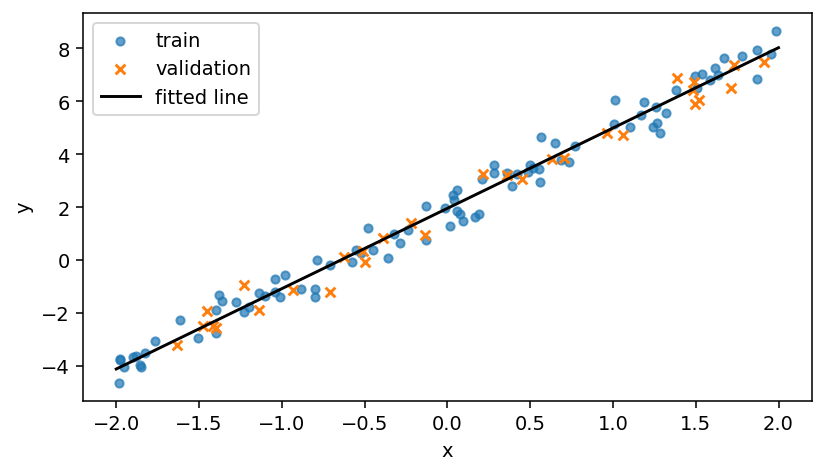

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

rng = np.random.default_rng(7)
X = rng.uniform(-2, 2, size=(120, 1))
y = 3 * X[:, 0] + 2 + rng.normal(0, 0.5, size=len(X))
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=7
)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_valid)
mse = mean_squared_error(y_valid, pred)
print("train / valid:", len(X_train), len(X_valid))
print(f"w={model.coef_[0]:.4f}, b={model.intercept_:.4f}")
print(f"valid MSE={mse:.4f}, RMSE={np.sqrt(mse):.4f}, R2={r2_score(y_valid, pred):.4f}")

grid = np.linspace(-2, 2, 100).reshape(-1, 1)
plt.figure(figsize=(6, 3.5))
plt.scatter(X_train[:, 0], y_train, s=18, label="train", alpha=0.7)
plt.scatter(X_valid[:, 0], y_valid, s=25, label="validation", marker="x")
plt.plot(grid[:, 0], model.predict(grid), color="black", label="fitted line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.tight_layout(); plt.show()


**코드 수정 문제**

1. `DummyRegressor(strategy="mean")`를 추가하세요. 입력과 관계없이 학습 정답의 평균만 예측하는 기준 모델입니다.
2. 동일한 학습·검증 세트로 두 모델의 MSE를 비교하고, 검증 MSE가 얼마나 감소했는지 비율을 계산하세요.
3. `y_valid.mean()`을 기준 모델에 직접 넣으면 왜 평가 목적에 맞지 않나요?

**정답 — 예제의 분할과 선형 모델을 사용합니다.**


In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_mse = mean_squared_error(y_valid, dummy.predict(X_valid))
linear_mse = mean_squared_error(y_valid, model.predict(X_valid))
improvement = 1 - linear_mse / dummy_mse
print(f"mean baseline MSE={dummy_mse:.4f}")
print(f"linear regression MSE={linear_mse:.4f}")
print(f"relative MSE reduction={improvement:.1%}")
print("baseline fitted from training mean:", np.isclose(dummy.constant_.item(), y_train.mean()))


mean baseline MSE=12.2226
linear regression MSE=0.1821
relative MSE reduction=98.5%
baseline fitted from training mean: True


**실행 결과 해설**

검증 환경에서 기울기는 약 3.0358, 절편은 약 1.9566입니다.
검증 MSE는 평균 예측 기준의 약 12.2226에서 선형 회귀의 약 0.1821로 줄었습니다.
학습된 기울기는 원래 생성 규칙의 3, 절편은 2와 가깝습니다. 잡음 때문에 정확히 일치할 필요는 없습니다.
선형 회귀는 입력을 활용하므로 평균만 예측하는 기준 모델보다 검증 MSE가 크게 줄어듭니다.
단순히 “MSE가 0.3이다”라고 말하기보다, 기준 모델과 비교하면 개선 정도를 해석하기 쉽습니다.

MSE 감소율은 `1 - 모델 MSE / 기준 MSE`입니다. 음수라면 기준 모델보다 나쁜 것입니다.
검증 정답 평균으로 기준 모델을 만들면 평가하려는 데이터의 정답 정보를 학습에 사용하게 됩니다.
이번 예제의 R²도 함께 출력하지만, 기준 모델의 실제 holdout 성능과 동일한 정의는 아닙니다.
R²의 기준은 평가 정답의 평균이며, 새 데이터에서 음수가 될 수도 있습니다.

**완료 기준:** fit에 사용하는 데이터, 성능 측정에 사용하는 데이터, 기준 모델의 역할을 설명하세요.


## 2회 — 스케일링과 Pipeline: 전처리도 학습이다

**핵심 개념**

KNN은 가까운 학습 샘플을 찾아 분류합니다. 거리 계산에서는 수치 범위가 큰 특성이 더 큰 영향을 줄 수 있습니다.
`StandardScaler`는 학습 세트에서 평균과 표준편차를 추정하고 특성을 표준화합니다.
평균·표준편차도 데이터에서 추정하는 값이므로 검증 정보를 포함하면 데이터 누수가 생깁니다.

`Pipeline`에 스케일러와 모델을 넣으면 fit 시 전처리도 학습 세트에만 맞춰집니다.
predict 시에는 학습 때 구한 값으로 검증 입력을 변환합니다.
이번에는 두 반달 모양의 이진 분류 데이터를 만들고 첫 특성에만 1000을 곱해 단위를 바꿉니다.
정답의 의미나 데이터의 정보량을 바꾸지 않고, 거리에서 단위가 미치는 영향을 관찰합니다.


In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=600, noise=0.25, random_state=7)
X[:, 0] *= 1000
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=7
)
plain = KNeighborsClassifier(n_neighbors=11)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
for name, estimator in [("unscaled", plain), ("scaled", scaled)]:
    estimator.fit(X_train, y_train)
    acc = accuracy_score(y_valid, estimator.predict(X_valid))
    print(f"{name}: validation accuracy={acc:.4f}")
print("scaler mean from training:", scaled[0].mean_.round(3).tolist())


unscaled: validation accuracy=0.6733
scaled: validation accuracy=0.9400
scaler mean from training: [499.637, 0.284]


**코드 수정 문제**

1. 다음 누수 코드를 Pipeline으로 바꾸세요. `X_scaled`를 분할하는 대신 원래 X를 먼저 분할해야 합니다.

```python
X_scaled = StandardScaler().fit_transform(X)  # 분할 전에 전체 데이터로 fit
X_train, X_valid, y_train, y_valid = train_test_split(X_scaled, y, random_state=7)
```

2. 예제와 **같은 분할**을 사용해 이웃 수 k를 1, 11, 51로 바꾸고 학습·검증 정확도를 함께 비교하세요.
3. 검증 데이터에 `scaler.fit_transform(X_valid)`를 다시 호출하면 왜 잘못되나요?

**정답 — 원본 X를 분리한 예제 변수와 Pipeline을 사용합니다.**


In [5]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for k in [1, 11, 51]:
    estimator = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    estimator.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, estimator.predict(X_train))
    valid_acc = accuracy_score(y_valid, estimator.predict(X_valid))
    print(f"k={k:2d}: train={train_acc:.4f}, valid={valid_acc:.4f}")
print("scaler statistics match train:", np.allclose(scaled[0].mean_, X_train.mean(axis=0)))


k= 1: train=1.0000, valid=0.9333
k=11: train=0.9711, valid=0.9400
k=51: train=0.9489, valid=0.9333
scaler statistics match train: True


**실행 결과 해설**

검증 환경에서 정확도는 스케일링 전 약 0.6733에서 스케일링 후 약 0.9400으로 높아졌습니다.
스케일링 전후의 검증 정확도를 비교하세요. 이 데이터에서는 단위를 조정하면 두 특성을 더 균형 있게 활용합니다.
스케일링이 모든 모델과 데이터에서 반드시 성능을 올리는 것은 아닙니다.
1-NN은 자기 자신을 이웃으로 찾으므로, 이 중복 없는 데이터에서 학습 정확도가 1이 됩니다.
그래도 검증 정확도가 1이 되는 것은 아닙니다. 학습 데이터 적합과 일반화는 다릅니다.
이웃 수가 커지면 더 넓은 영역을 평균내므로 경계가 단순해질 수 있습니다.

검증에서 스케일러를 다시 fit하면 학습 때와 다른 좌표계로 입력을 변환합니다.
`transform(X_valid)`만 사용하거나 Pipeline의 predict에 원본 검증 입력을 넣어야 합니다.
이웃 수를 비교해 본 세트는 이미 모델 선택에 사용한 **검증 세트**입니다.

**완료 기준:** 전처리 fit과 transform의 차이, Pipeline이 누수를 줄이는 이유를 설명하세요.


## 3회 — 로지스틱 회귀: 확률과 최종 판단은 다르다

**핵심 개념**

이진 로지스틱 회귀는 $z=w^Tx+b$를 계산하고 $P(y=1\mid x)=\sigma(z)$로 변환합니다.
이름에 회귀가 들어가지만 여기서는 분류 모델입니다.
딥러닝 과제의 로짓·Sigmoid·BCE와 연결되며, scikit-learn의 LogisticRegression은 기본적으로 규제도 적용합니다.
`predict_proba`는 확률 추정값이고, 임계값을 적용한 결과가 최종 클래스입니다.

| 지표 | 의미 |
|---|---|
| 정확도 | 전체 중 맞힌 비율 |
| 정밀도 | 1로 예측한 것 중 실제 1인 비율 |
| 재현율 | 실제 1 중 찾아낸 비율 |
| F1 | 정밀도와 재현율의 조화평균 |

양성(라벨 1)이 적으면 항상 0만 예측해도 정확도가 높을 수 있습니다.
여기서는 로그 손실로 확률 예측을 평가하고, 임계값에 따라 분류 지표가 달라지는지도 봅니다.
임계값은 검증 데이터에서 고르고 최종 테스트에서는 다시 고르지 않습니다.


In [6]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

X, y = make_classification(
    n_samples=1200, n_features=8, n_informative=4, n_redundant=2,
    weights=[0.85, 0.15], class_sep=1.0, flip_y=0.02, random_state=7
)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=7
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=7
)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
p_valid = model.predict_proba(X_valid)[:, 1]  # 이 모델의 classes_가 [0, 1]이므로 1번 열
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("train / valid / final test:", len(X_train), len(X_valid), len(X_test))
print(f"positive fraction in training={y_train.mean():.3f}")
print(f"dummy accuracy={accuracy_score(y_valid, dummy.predict(X_valid)):.4f}, "
      f"dummy F1={f1_score(y_valid, dummy.predict(X_valid), zero_division=0):.4f}")
print(f"validation log loss={log_loss(y_valid, model.predict_proba(X_valid)):.4f}")
for threshold in [0.5, 0.3]:
    pred = (p_valid >= threshold).astype(int)
    print(f"threshold={threshold:.1f}: accuracy={accuracy_score(y_valid, pred):.4f}, "
          f"precision={precision_score(y_valid, pred, zero_division=0):.4f}, "
          f"recall={recall_score(y_valid, pred):.4f}, F1={f1_score(y_valid, pred):.4f}")


train / valid / final test: 720 240 240
positive fraction in training=0.157
dummy accuracy=0.8417, dummy F1=0.0000
validation log loss=0.2599
threshold=0.5: accuracy=0.8958, precision=0.6970, recall=0.6053, F1=0.6479
threshold=0.3: accuracy=0.8750, precision=0.5800, recall=0.7632, F1=0.6591


**코드 수정 문제**

1. 임계값 후보를 `[0.1, 0.2, ..., 0.9]`로 늘리세요.
2. **검증 F1이 최대**인 임계값을 선택하세요. 같은 F1이면 먼저 등장한 임계값을 선택해도 됩니다.
3. 모델을 재학습하지 않고, 선택한 임계값을 고정한 뒤 최종 테스트 F1과 혼동행렬을 한 번 출력하세요.
4. 임계값만 바꿨을 때 모델의 로짓과 예측 확률도 바뀌나요?

**정답 — 검증에서 선택하고 테스트에서 평가합니다.**


In [7]:
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix

thresholds = np.arange(1, 10) / 10
valid_scores = [f1_score(y_valid, p_valid >= t, zero_division=0) for t in thresholds]
best_index = int(np.argmax(valid_scores))
best_threshold = thresholds[best_index]
print("validation (threshold, F1):", [(round(float(t), 1), round(float(s), 4)) for t, s in zip(thresholds, valid_scores)])
print(f"chosen threshold={best_threshold:.1f}")
p_test = model.predict_proba(X_test)[:, 1]
test_pred = (p_test >= best_threshold).astype(int)
print(f"final test F1={f1_score(y_test, test_pred):.4f}")
print("confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))


validation (threshold, F1): [(0.1, 0.5161), (0.2, 0.6392), (0.3, 0.6591), (0.4, 0.6582), (0.5, 0.6479), (0.6, 0.6349), (0.7, 0.6102), (0.8, 0.6071), (0.9, 0.5098)]
chosen threshold=0.3
final test F1=0.6087
confusion matrix [[TN, FP], [FN, TP]]:
[[176  26]
 [ 10  28]]


**실행 결과 해설**

항상 0을 예측하는 기준 모델은 정확도 0.8417이지만 F1은 0입니다.
검증에서 선택한 임계값은 0.3이며, 이 임계값의 최종 테스트 F1은 약 0.6087입니다.


임계값을 낮추면 양성으로 예측하는 샘플 집합이 커지므로, 같은 확률 예측에서 재현율은 줄어들지 않습니다.
정밀도는 반드시 일정 방향으로 변하지 않으며, F1이 항상 좋아지는 것도 아닙니다.
임계값을 바꾸어도 이미 학습한 가중치와 확률은 그대로입니다. 따라서 로그 손실도 바뀌지 않습니다.

검증에서 가장 좋은 F1이 최종 테스트에서 그대로 나오지 않는 것은 자연스러운 표본 차이입니다.
테스트 결과를 보고 임계값을 다시 고르면 그 테스트도 모델 선택에 사용한 데이터가 됩니다.
여기서는 모델을 고정하고 임계값만 선택했습니다. 모델을 재학습하면 확률 분포가 바뀔 수 있으므로
검증에서 고른 임계값이 그대로 최적인지는 별도로 확인해야 합니다.

**완료 기준:** 확률 예측과 임계값 결정, 정확도와 F1의 차이를 설명하세요.


## 4회 — 다항 회귀와 Ridge: 복잡하면 더 잘 맞을까?

**핵심 개념**

`PolynomialFeatures`는 입력 x를 $x,x^2,\dots,x^d$로 확장합니다.
선형 회귀가 이 특성에 선형으로 결합해도 원래 x에 대해서는 곡선이 됩니다.
모델이 단순해 학습 관계를 충분히 설명하지 못하면 과소적합,
학습 잡음까지 맞추어 새 데이터 오차가 커지면 과적합을 의심합니다.

Ridge는 제곱 오차에 $\alpha\lVert w\rVert_2^2$ 패널티를 추가합니다.
대략적으로 `alpha`가 클수록 가중치 크기를 더 강하게 제한합니다.
절편은 일반적으로 같은 방식으로 벌점 주지 않습니다.
이 실습에서는 다항 특성을 만든 뒤 표준화하고 규제를 적용하므로, alpha의 의미는 이 특성 스케일에 연결됩니다.
PyTorch에서 본 학습률과 Ridge의 alpha는 다릅니다. alpha는 목적함수의 규제 강도입니다.


degree 1            : train MSE=0.25406, valid MSE=0.25513
degree 2            : train MSE=0.03177, valid MSE=0.04068
degree 15           : train MSE=0.02220, valid MSE=777.63456
degree 15 + Ridge   : train MSE=0.02936, valid MSE=0.04066


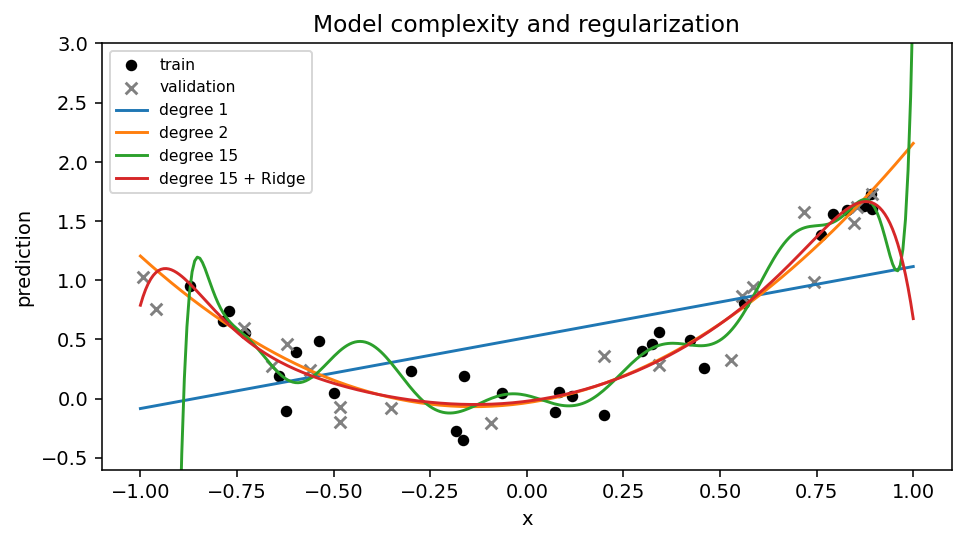

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(12)
X = rng.uniform(-1, 1, size=(50, 1))
y = 1.5 * X[:, 0] ** 2 + 0.5 * X[:, 0] + rng.normal(0, 0.2, size=len(X))
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.4, random_state=7)

def polynomial_model(degree, alpha=None):
    regressor = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), regressor)

models = {
    "degree 1": polynomial_model(1),
    "degree 2": polynomial_model(2),
    "degree 15": polynomial_model(15),
    "degree 15 + Ridge": polynomial_model(15, alpha=0.1),
}
grid = np.linspace(-1, 1, 300).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(X_train[:, 0], y_train, s=24, label="train", color="black")
plt.scatter(X_valid[:, 0], y_valid, marker="x", label="validation", color="gray")
for name, model in models.items():
    model.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    valid_mse = mean_squared_error(y_valid, model.predict(X_valid))
    print(f"{name:20s}: train MSE={train_mse:.5f}, valid MSE={valid_mse:.5f}")
    plt.plot(grid[:, 0], model.predict(grid), label=name)
plt.ylim(-0.6, 3.0)  # 다른 곡선도 보이도록 표시 범위 고정; 범위 밖 값은 잘릴 수 있음
plt.xlabel("x"); plt.ylabel("prediction"); plt.legend(fontsize=8)
plt.title("Model complexity and regularization"); plt.tight_layout(); plt.show()


**코드 수정 문제**

1. 15차 다항 회귀의 Ridge alpha를 0.001, 0.1, 10으로 바꾸고 학습·검증 MSE를 출력하세요.
2. 검증 MSE가 가장 작은 alpha를 고르세요. 가장 큰 alpha가 항상 가장 좋은가요?
3. `include_bias=True`로 만든 상수 특성과 회귀 모델의 절편을 함께 두는 대신, 여기서 왜 `False`를 사용했는지 설명하세요.

**정답 — 예제의 함수와 분할을 사용합니다.**


In [9]:
from sklearn.metrics import mean_squared_error

records = []
for alpha in [0.001, 0.1, 10]:
    estimator = polynomial_model(15, alpha=alpha)
    estimator.fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, estimator.predict(X_train))
    valid_mse = mean_squared_error(y_valid, estimator.predict(X_valid))
    records.append((alpha, train_mse, valid_mse))
    print(f"alpha={alpha:g}: train MSE={train_mse:.5f}, valid MSE={valid_mse:.5f}")
best_alpha = min(records, key=lambda row: row[2])[0]
print("best alpha among these candidates:", best_alpha)


alpha=0.001: train MSE=0.02587, valid MSE=6.46074
alpha=0.1: train MSE=0.02936, valid MSE=0.04066
alpha=10: train MSE=0.04598, valid MSE=0.18214
best alpha among these candidates: 0.1


**실행 결과 해설**

검증 환경에서 2차 모델의 검증 MSE는 약 0.04068입니다.
규제 없는 15차는 학습 MSE가 약 0.02220이지만 검증 MSE가 약 777.63456으로 커집니다.
같은 15차에 Ridge alpha=0.1을 적용하면 검증 MSE는 약 0.04066입니다.
차수를 높이면 학습 MSE는 줄어들 수 있지만 검증 MSE도 함께 줄어든다는 보장은 없습니다.
이 데이터는 2차 관계에서 생성했으므로 1차는 관계를 충분히 설명하지 못하고,
규제 없는 15차는 작은 학습 세트의 잡음에 민감해질 수 있습니다.
그림에서는 y축 범위를 벗어난 곡선 일부가 잘립니다. 숫자로 출력한 MSE에는 그 예측도 반영됩니다.

Ridge가 고차 계수의 크기를 제한하면 검증 오차가 줄 수 있습니다.
그러나 alpha를 너무 크게 하면 필요한 패턴까지 억제하므로 강한 규제가 언제나 좋지는 않습니다.
이번에 고른 alpha는 현재 분할·후보 집합에 대한 선택이며, 일반적인 최적값이 아닙니다.
5회에서는 단 한 번의 분할에 대한 의존도를 줄이기 위해 교차검증을 사용합니다.

`include_bias=False`는 중복 상수 특성을 만들지 않기 위한 선택입니다. 회귀 모델이 절편을 따로 추정합니다.

**완료 기준:** 다항 차수, 규제 강도, 학습률이 각각 무엇을 바꾸는지 구분하세요.


## 5회 — 트리와 랜덤포레스트를 교차검증으로 비교하기

**핵심 개념**

결정트리는 “특성값이 기준보다 작은가?” 같은 분할을 반복합니다.
깊은 트리는 복잡한 경계를 만들지만 학습 데이터에 과적합할 수 있습니다.
랜덤포레스트는 여러 트리에 표본·특성의 무작위성을 부여하고 예측을 결합합니다.
트리 분할은 일반적으로 특성의 단위 변경에 덜 민감하므로 여기서는 스케일러를 사용하지 않습니다.

K-fold 교차검증은 데이터를 K개로 나누고, 매번 K-1개로 학습해 남은 하나로 검증합니다.
분류에서는 `StratifiedKFold`로 클래스 비율을 대략 유지합니다.
각 폴드에서 모델을 새로 fit합니다. 한 번 fit한 모델을 모든 폴드에 재사용하지 않습니다.

평균 점수뿐 아니라 폴드 간 표준편차도 출력합니다.
표준편차는 이 분할에서의 변동 정도이지, 자동으로 신뢰구간이 되지는 않습니다.
교차검증 점수를 보고 모델을 고른 뒤에는 별도 테스트가 여전히 필요합니다.


In [10]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

X, y = make_moons(n_samples=600, noise=0.25, random_state=7)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
models = {
    "tree depth=3": DecisionTreeClassifier(max_depth=3, random_state=7),
    "unrestricted tree": DecisionTreeClassifier(random_state=7),
    "random forest": RandomForestClassifier(n_estimators=100, random_state=7, n_jobs=1),
}
for name, model in models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring="f1", return_train_score=True, n_jobs=1)
    print(f"{name:20s}: train F1={scores['train_score'].mean():.4f}, "
          f"CV F1={scores['test_score'].mean():.4f} +/- {scores['test_score'].std():.4f}")


tree depth=3        : train F1=0.9203, CV F1=0.9093 +/- 0.0177
unrestricted tree   : train F1=1.0000, CV F1=0.9289 +/- 0.0190
random forest       : train F1=1.0000, CV F1=0.9501 +/- 0.0146


**코드 수정 문제**

1. 트리의 `min_samples_leaf`를 1, 5, 20으로 바꾸고 학습 F1과 CV F1을 비교하세요.
2. 각 후보에 동일한 `StratifiedKFold` 설정을 사용하세요.
3. 가장 좋은 후보를 고른 뒤, 그 후보만 3-fold로 실행해 5-fold 평균과 비교하세요. CV 점수가 같아야 하나요?

**정답 — 예제의 X, y, cv를 사용합니다.**


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

rows = []
for leaf in [1, 5, 20]:
    estimator = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=7)
    scores = cross_validate(estimator, X, y, cv=cv, scoring="f1", return_train_score=True)
    score = scores["test_score"].mean()
    rows.append((leaf, score))
    print(f"min_samples_leaf={leaf:2d}: train F1={scores['train_score'].mean():.4f}, CV F1={score:.4f}")
best_leaf = max(rows, key=lambda row: row[1])[0]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=7)
scores3 = cross_validate(DecisionTreeClassifier(min_samples_leaf=best_leaf, random_state=7),
                         X, y, cv=cv3, scoring="f1")
print(f"chosen leaf={best_leaf}; 3-fold F1={scores3['test_score'].mean():.4f}")


min_samples_leaf= 1: train F1=1.0000, CV F1=0.9289
min_samples_leaf= 5: train F1=0.9755, CV F1=0.9354
min_samples_leaf=20: train F1=0.9457, CV F1=0.9208
chosen leaf=5; 3-fold F1=0.9450


**실행 결과 해설**

검증 환경에서 최소 리프 크기 1, 5, 20의 평균 CV F1은 각각 약 0.9289, 0.9354, 0.9208입니다.
적당한 제한은 도움이 되지만 제한을 계속 늘린다고 성능이 계속 좋아지지는 않습니다.
무제한 트리는 학습 F1이 매우 높아도 CV 점수는 낮을 수 있습니다.
학습·검증 점수의 차이가 크면 과적합을 의심할 근거가 됩니다. 점수 차이만으로 원인을 모두 확정하지는 않습니다.
최소 리프 크기를 늘리면 분할이 제한되어 학습 점수는 낮아질 수 있지만 검증 점수는 좋아질 수 있습니다.
너무 크게 제한하면 과소적합할 수도 있습니다.

랜덤포레스트는 단일 트리보다 안정적인 경우가 많지만, 이번 한 데이터의 순위가 항상 유지되는 것은 아닙니다.
3-fold와 5-fold는 각 학습 세트의 크기와 검증 샘플 구성이 달라 평균이 달라도 정상입니다.
`cross_validate` 반환값의 `test_score`라는 이름은 **각 폴드의 검증 점수**를 뜻합니다.
독립적인 최종 테스트 성능과 혼동하지 마세요.

**완료 기준:** 트리의 복잡도 제어와 교차검증의 역할을 구분하고, 폴드 점수와 최종 테스트 점수의 차이를 설명하세요.


## 6회 — Pipeline + GridSearchCV로 모델 선택 완성하기

**핵심 개념**

`GridSearchCV`는 후보 하이퍼파라미터마다 교차검증을 수행합니다.
모델 파라미터(예: 회귀 계수)는 fit에서 학습되고, 하이퍼파라미터(예: KNN의 k)는 우리가 후보를 지정합니다.
Pipeline 전체를 검색에 넣어 전처리도 각 폴드의 학습 부분에서만 fit하게 합니다.
`refit=True`이면 가장 좋은 설정을 고른 뒤 개발 데이터 전체로 다시 학습합니다.

실습 흐름은 **최종 테스트 분리 → 개발 세트에서만 검색 → 설정 확정 → 최종 테스트 한 번 평가**입니다.
최적 후보의 CV 점수는 선택 과정에서 높게 평가될 수 있으므로 최종 테스트 점수와 같은 의미가 아닙니다.
데이터가 작은 상황에서 모델 선택 자체의 성능을 평가하려면 중첩 교차검증도 고려할 수 있습니다.

2회의 Pipeline, 3회의 F1, 5회의 동일한 CV 분할을 합칩니다.
1~5회의 결과를 그대로 평가하는 것이 아니라, 이 회차 안에서 새로운 분할을 고정한 독립 실습입니다.
이전 회차에서는 보지 않은 데이터셋 시드 17을 사용합니다.


In [12]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

X, y = make_moons(n_samples=600, noise=0.3, random_state=17)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=17
)
pipeline = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
grid = [
    {"model": [LogisticRegression(max_iter=1000)], "model__C": [0.1, 1, 10]},
    {"model": [KNeighborsClassifier()], "model__n_neighbors": [3, 11, 21]},
]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)
search = GridSearchCV(pipeline, grid, scoring="accuracy", cv=cv, refit=True, n_jobs=1)
search.fit(X_dev, y_dev)
print("development / untouched final test:", len(X_dev), len(X_test))
print("best parameters on development CV:", search.best_params_)
print(f"best development CV accuracy={search.best_score_:.4f}")
# 검색 중에는 최종 테스트를 평가하지 않음


development / untouched final test: 480 120
best parameters on development CV: {'model': KNeighborsClassifier(), 'model__n_neighbors': 11}
best development CV accuracy=0.8854


**코드 수정 문제**

1. 검색 지표를 `accuracy`에서 `f1`으로 바꾸세요. 어떤 라벨을 양성으로 보는지도 확인하세요.
2. 랜덤포레스트 후보를 추가하세요. 트리 수 100, 깊이 `[3, None]`, 최소 리프 크기 `[1, 5]`를 탐색하세요.
   트리 후보는 `scale="passthrough"`로 두세요. 나머지 후보는 기존 스케일러를 유지합니다.
3. 같은 개발 세트·CV 설정에서 다시 검색한 뒤 후보 상위 3개의 평균 CV F1을 출력하세요.
4. 선택된 모델로만 최종 테스트 정확도·F1·혼동행렬을 출력하세요. 테스트를 보고 후보를 다시 고르지 마세요.

**정답 — 예제의 pipeline, grid, cv, 분할 데이터를 사용합니다.**


In [13]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

extended_grid = grid + [{
    "scale": ["passthrough"],
    "model": [RandomForestClassifier(n_estimators=100, random_state=17, n_jobs=1)],
    "model__max_depth": [3, None],
    "model__min_samples_leaf": [1, 5],
}]
final_search = GridSearchCV(pipeline, extended_grid, scoring="f1", cv=cv, refit=True, n_jobs=1)
final_search.fit(X_dev, y_dev)
order = np.argsort(-final_search.cv_results_["mean_test_score"])
for rank, index in enumerate(order[:3], start=1):
    params = final_search.cv_results_["params"][index]
    print(f"rank {rank}: CV F1={final_search.cv_results_['mean_test_score'][index]:.4f}, {params}")
print("chosen:", final_search.best_params_)
pred = final_search.predict(X_test)
print(f"final test accuracy={accuracy_score(y_test, pred):.4f}, F1={f1_score(y_test, pred):.4f}")
print("confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, pred, labels=[0, 1]))


rank 1: CV F1=0.8859, {'model': KNeighborsClassifier(), 'model__n_neighbors': 11}
rank 2: CV F1=0.8802, {'model': RandomForestClassifier(n_jobs=1, random_state=17), 'model__max_depth': None, 'model__min_samples_leaf': 5, 'scale': 'passthrough'}
rank 3: CV F1=0.8798, {'model': KNeighborsClassifier(), 'model__n_neighbors': 21}
chosen: {'model': KNeighborsClassifier(), 'model__n_neighbors': 11}
final test accuracy=0.8500, F1=0.8448
confusion matrix [[TN, FP], [FN, TP]]:
[[53  7]
 [11 49]]


**실행 결과 해설**

출력의 CV F1은 개발 세트 내부의 검증 점수 평균이며, 최종 테스트 F1은 별도 120개 샘플의 점수입니다.
검증 환경에서 선택된 모델은 k=11인 KNN입니다. 평균 CV F1은 약 0.8859,
최종 테스트 F1은 약 0.8448입니다.


두 점수가 다르더라도 바로 코드 오류로 판단하지 않습니다. 학습 크기·샘플 구성·선택 편향이 다릅니다.
검색 목표를 F1로 바꾸면 평균 정확도로 골랐을 때와 선택 후보가 달라질 수도 있습니다.
이번 반달 데이터는 균형 잡힌 이진 분류이지만, 두 지표가 언제나 같은 순위를 주는 것은 아닙니다.

로지스틱 회귀의 C는 규제 강도의 역수이므로 작을수록 규제가 강합니다.
Ridge의 alpha와 같은 방향으로 해석하지 마세요. 두 모델의 손실과 규제 정의도 다릅니다.
선택된 모델의 `predict` 기본 결정 규칙을 사용했으며, 이 회차에서는 임계값을 추가 튜닝하지 않았습니다.

랜덤포레스트 후보에서 scale을 passthrough로 지정해도 나머지 후보는 원래 Pipeline의 StandardScaler를 사용합니다.
GridSearchCV는 후보·폴드마다 복제한 모델을 fit하므로 앞 후보의 학습 상태를 이어받지 않습니다.
최종 테스트를 보고 다음 버전을 고르는 일을 반복하면 그 세트도 사실상 검증 세트가 됩니다.

**완료 기준:** 최적 모델 이름보다, 전처리·후보·지표·분할·최종 평가 과정을 함께 설명하세요.


## 마무리 복습

1. 학습·검증·최종 테스트 세트의 역할은 무엇인가요?
2. 전체 데이터에 StandardScaler를 fit한 뒤 CV를 돌리면 왜 문제가 될까요?
3. 항상 다수 클래스만 예측하는 모델의 정확도만 보면 무엇을 놓치나요?
4. 다항 차수를 높일 때 학습 MSE와 검증 MSE는 각각 어떻게 변할 수 있나요?
5. Ridge의 alpha와 LogisticRegression의 C는 규제 강도에 어떤 방향으로 작용하나요?
6. 교차검증에서 가장 높은 평균 점수를 얻었다는 사실이 새 데이터에서도 우승을 보장하나요?

**간단 정답:** ① 학습 / 선택 / 선택 후 최종 평가
② 폴드 검증 자료의 통계가 전처리에 유입됨
③ 소수 클래스 탐지 성능
④ 학습 MSE는 줄어들어도 검증 MSE는 커질 수 있음
⑤ alpha↑는 규제 강화, C↓는 규제 강화
⑥ 아니요. 표본 변동과 선택 편향이 있으며 별도 평가가 필요함.

## 학습 일지

| 변경한 코드 | 실행 전 예상 | 실제 결과 | 이유 |
|---|---|---|---|
| 예: 1-NN → 11-NN | 학습 정확도는 낮아지고 검증은 개선될 수 있음 | 직접 기록 | 더 넓은 이웃으로 결정 |

**스스로 설명할 문장:** “나는 ___ 데이터에서 ___ 지표로 ___ 후보를 비교했고,
전처리는 ___에서만 fit했다. 최종 테스트는 ___ 시점에 평가했다.”

## 공식 참고 문서

API와 평가 원칙은 scikit-learn 공식 문서를 참고했습니다. 과제·합성 데이터·실험 해설은 이 노트북용으로 구성했습니다.

- [데이터 누수와 일관된 전처리](https://scikit-learn.org/stable/common_pitfalls.html)
- [교차검증](https://scikit-learn.org/stable/modules/cross_validation.html)
- [분류 임계값](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [하이퍼파라미터 탐색](https://scikit-learn.org/stable/modules/grid_search.html)
- [선형 모델과 규제](https://scikit-learn.org/stable/modules/linear_model.html)

**다음 확장:** 범주형 특성이 있는 실제 표 데이터에 ColumnTransformer를 적용하고,
결측치 처리·인코딩도 Pipeline에 포함해 같은 평가 절차를 반복해 보세요.
